# 07 · Evaluar un sistema RAG

Hasta ahora juzgábamos los resultados leyéndolos. Eso no escala y oculta la propiedad más importante de un
sistema RAG: **si está mejorando o empeorando**. Cada cambio que haces (un nuevo tamaño de fragmento, un modelo
de embeddings, un prompt, un umbral) arregla unas preguntas y rompe otras sin avisar. Sin una batería fija de
preguntas con respuesta conocida navegas a ojo.

Este módulo construye esa batería como es debido, la califica automáticamente, muestra dónde la calificación
automática es **errónea** (lo será), mide cuánta evidencia puede dar de verdad una batería de este tamaño y
termina con una comparación antes y después sobre preguntas escritas *después* del arreglo.

**Aprenderás**
1. Qué contiene una buena batería de preguntas: cobertura, paráfrasis, identificadores exactos y **trampas**
2. Referencias tomadas de la fuente, nunca del sistema que se evalúa
3. Un calificador automático (datos requeridos, afirmaciones prohibidas, fuente correcta) y dos formas en que falla
4. Comprobaciones de fidelidad y de citas basadas en reglas, y lo que no pueden ver
5. Métricas de recuperación (hit@k, MRR) junto a métricas de respuesta (corrección, precisión y exhaustividad del rechazo)
6. Intervalos de confianza por bootstrap, y cuántas preguntas necesitas para distinguir dos sistemas
7. Una comparación antes y después en la que el segundo conjunto **no** se usó para construir el arreglo

## 1. La batería

Cuarenta preguntas en dos conjuntos sobre el manual de Harbourview. Cada una lleva:

* el **pasaje correcto** que contiene la respuesta (o `None` cuando el manual no puede responder);
* **datos requeridos** como expresiones regulares que la respuesta debe contener, y **afirmaciones prohibidas**
  que no debe contener;
* un **tipo**: `direct`, `paraphrase`, `identifier` o `trap`.

El **conjunto 1** (20 preguntas) es el que miramos mientras construimos. El **conjunto 2** (20 preguntas) se
escribe *después* y solo se usa para comprobar que un arreglo generaliza. Las **trampas** son preguntas que un
sistema descuidado responde con seguridad y mal: una turbina que no existe (`HV99`) y un resultado que el manual
nunca da (la disponibilidad del último mes, cuando solo indica un *objetivo*). Una batería sin trampas premia a
los sistemas que nunca dicen "no lo sé".

Las referencias salen de leer el manual (los datos que hay detrás del sistema), **nunca de ejecutar el
sistema**. Una referencia copiada de la salida del sistema solo mide que el sistema coincide consigo mismo.

In [1]:
# El manual de Harbourview: 22 pasajes, ficticio, escrito para este curso
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

In [2]:
import re, math, time, textwrap
import numpy as np
import matplotlib.pyplot as plt

# (id, pregunta, pasaje correcto o None, patrones de datos requeridos, patrones prohibidos, tipo)
SET1 = [
    ("s01", "What wave height stops the crew boats from sailing?", "p02", [r"1\.5 ?m"], [], "direct"),
    ("s02", "How often is the gearbox oil sampled?", "p07", [r"six months"], [], "direct"),
    ("s03", "Who may work alone inside a nacelle?", "p03", [r"forbidden"], [], "paraphrase"),
    ("s04", "What is the rotor diameter of a turbine?", "p04", [r"164 ?m"], [], "direct"),
    ("s05", "What do I do if the pitch fault comes back after a reset?", "p10", [r"replace the hydraulic accumulator"], [], "direct"),
    ("s06", "When must a Level 3 alarm be attended on site?", "p09", [r"24 hours"], [], "direct"),
    ("s07", "How soon must an injury be reported?", "p19", [r"one hour"], [], "direct"),
    ("s08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", [r"300 ?MW"], [r"8\.0 ?MW"], "paraphrase"),
    ("s09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", [r"HV01 to HV08"], [], "paraphrase"),
    ("s10", "How many spare wind vanes are kept in stock?", "p16", [r"four wind vanes"], [], "direct"),
    ("s11", "What qualification do I need before getting on the boat?", "p01", [r"GWO Basic Safety Training"], [], "paraphrase"),
    ("s12", "When can the turbines restart after a blackout?", "p12", [r"10 minutes"], [], "paraphrase"),
    ("s13", "When can a helicopter be used?", "p17", [r"medical evacuation"], [], "direct"),
    ("s14", "What happens when a dolphin is seen near the piling work?", "p13", [r"pause"], [], "paraphrase"),
    ("s15", "What is the price of electricity per MWh?", None, [], [], "trap"),
    ("s16", "Who is the chief executive of the operating company?", None, [], [], "trap"),
    ("s17", "What is the rated power of turbine HV99?", None, [], [], "trap"),
    ("s18", "What availability did the farm achieve last month?", None, [], [], "trap"),
    ("s19", "How many turbines does the farm have?", "p04", [r"40 turbines"], [], "direct"),
    ("s20", "What is the cut-in wind speed?", "p04", [r"3 ?m/s"], [], "direct"),
]
SET2 = [
    ("t01", "Are boats cancelled when the sea is too rough?", "p02", [r"1\.5 ?m"], [], "paraphrase"),
    ("t02", "Can I go up the tower alone to fix something?", "p03", [r"forbidden"], [], "paraphrase"),
    ("t03", "How big are the blades?", "p04", [r"164 ?m"], [], "paraphrase"),
    ("t04", "Who do I call in the middle of the night about an accident?", "p18", [r"control room line"], [], "paraphrase"),
    ("t05", "What if the oil in the gearbox gets dirty?", "p07", [r"filter change"], [], "paraphrase"),
    ("t06", "Do you stop work when whales or seals swim close?", "p13", [r"pause"], [], "paraphrase"),
    ("t07", "How much spare equipment is kept on shore?", "p16", [r"two pitch accumulators"], [], "paraphrase"),
    ("t08", "Is the farm allowed to produce at full output?", "p21", [r"300 ?MW"], [], "paraphrase"),
    ("t09", "What should new colleagues do before their first trip?", "p22", [r"induction"], [], "paraphrase"),
    ("t10", "How should rubbish and old oil be handled?", "p15", [r"brought ashore"], [], "paraphrase"),
    ("t11", "What does code PF-203 mean?", "p10", [r"low accumulator pressure"], [], "identifier"),
    ("t12", "alarm YW-110", "p11", [r"8 degrees"], [], "identifier"),
    ("t13", "ISO 4406 18/16/13", "p07", [r"filter change"], [], "identifier"),
    ("t14", "Where is OSS1?", "p05", [r"centre"], [], "identifier"),
    ("t15", "66 kV cables", "p21", [r"two cables"], [], "identifier"),
    ("t16", "What is the stock price of the operating company?", None, [], [], "trap"),
    ("t17", "What is the rotor diameter of turbine HV77?", None, [], [], "trap"),
    ("t18", "What was the monthly availability in July?", None, [], [], "trap"),
    ("t19", "How many people work on the farm?", None, [], [], "trap"),
    ("t20", "What is the cut-out wind speed?", None if False else "p04", [r"25 ?m/s"], [], "direct"),
]
BATTERY = SET1 + SET2
ids = [p[0] for p in PASSAGES]
chunks = [f"{section}. {text}" for _, section, text in PASSAGES]
from collections import Counter
print(len(BATTERY), "questions;", Counter(q[5] for q in BATTERY), "; unanswerable:", sum(q[2] is None for q in BATTERY))

40 questions; Counter({'paraphrase': 16, 'direct': 11, 'trap': 8, 'identifier': 5}) ; unanswerable: 8


## 2. Dos sistemas para comparar

Los sistemas evaluados son los de los módulos 01 y 02, pequeños para que la evaluación sea la protagonista:

* **Sistema A**: recuperación con BM25.
* **Sistema B**: recuperación híbrida, BM25 y embeddings MiniLM fusionados con Reciprocal Rank Fusion
  ponderada (peso de BM25 0,25, el mejor ajuste que encontramos en el módulo 02).

Ambos usan el mismo **generador extractivo** determinista (cita el pasaje principal y lo referencia como `[1]`)
y se niegan a responder cuando la recuperación parece demasiado débil. Un sistema devuelve la respuesta, el
pasaje que citó y si se negó.

In [3]:
STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
def tokens(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.tf = [{} for _ in docs]
        for i, d in enumerate(docs):
            for t in tokens(d):
                self.tf[i][t] = self.tf[i].get(t, 0) + 1
        self.len = np.array([sum(tf.values()) for tf in self.tf], dtype=float); self.avg = self.len.mean()
        df = {}
        for tf in self.tf:
            for t in tf:
                df[t] = df.get(t, 0) + 1
        self.idf = {t: math.log(1 + (len(docs) - c + 0.5) / (c + 0.5)) for t, c in df.items()}
    def scores(self, query):
        s = np.zeros(len(self.tf))
        for t in set(tokens(query)):
            if t in self.idf:
                for i, tf in enumerate(self.tf):
                    f = tf.get(t, 0)
                    if f:
                        s[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return s

from sentence_transformers import SentenceTransformer
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
E = model.encode(chunks, normalize_embeddings=True)
bm25 = BM25(chunks)
sem = lambda q: E @ model.encode(q, normalize_embeddings=True)

def rrf(scorers, weights, k=60):
    def fused(q):
        total = np.zeros(len(ids))
        for sc, w in zip(scorers, weights):
            for rank, i in enumerate(np.argsort(-sc(q)), start=1):
                total[i] += w / (k + rank)
        return total
    return fused

def quote(idx):
    return chunks[idx].split(". ", 1)[1]

def build_system(scorer, refuse, expand=None, entity_guard=False):
    def system(question):
        query = expand(question) if expand else question
        if entity_guard:
            for hv in re.findall(r"\bHV(\d+)\b", question):
                if not 1 <= int(hv) <= 40:
                    return dict(refused=True, cited=None, answer="That turbine does not exist in this farm.", ranking=[])
        s = scorer(query)
        order = np.argsort(-s)
        if refuse(question, query):
            return dict(refused=True, cited=None, answer="I cannot find that in the handbook.", ranking=[ids[i] for i in order])
        top = int(order[0])
        return dict(refused=False, cited=ids[top], answer=f"{quote(top)} [1]", ranking=[ids[i] for i in order])
    return system

A = build_system(bm25.scores, lambda q, e: bm25.scores(e).max() < 1.0)
hybrid = rrf([bm25.scores, sem], [0.25, 1.0])
B = build_system(hybrid, lambda q, e: bm25.scores(e).max() < 1.0 and sem(e).max() < 0.30)
for name, sys_ in [("A", A), ("B", B)]:
    r = sys_("What wave height stops the crew boats from sailing?")
    print(name, r["cited"], "|", r["answer"])

/home/patito/Developments/academy/rag-systems/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2882.53it/s]

A p02 | Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later. [1]
B p02 | Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later. [1]


## 3. El calificador automático, versión 1: expresiones regulares

El calificador más barato no necesita ningún modelo: una respuesta a una pregunta respondible es **correcta**
cuando contiene **todos los datos requeridos** y **ninguna afirmación prohibida**; una respuesta a una trampa es
correcta cuando el sistema **se niega**. Es rápido, determinista y gratuito, y puedes ejecutarlo en cada commit.
Sus límites son el resto de esta sección.

In [4]:
# Patrones de la versión 1: escritos deprisa, como se suele hacer. Dos tienen fallos a propósito (ver sección 4).
V1_OVERRIDES = {
    "s08": ([r"\d+(\.\d+)? ?MW"], []),        # "algún número de MW": débil, y sin afirmación prohibida
    "s12": ([r"10 min\b"], []),               # \b tras "min": demasiado estricto, el texto dice "minutes"
}

def grade_v1(q, out):
    qid, question, gold, req, forbid, kind = q
    if gold is None:
        return "correct" if out["refused"] else "wrong"
    if out["refused"]:
        return "missed"
    req, forbid = V1_OVERRIDES.get(qid, (req, forbid))
    ok = all(re.search(p, out["answer"], re.I) for p in req) and not any(re.search(p, out["answer"], re.I) for p in forbid)
    return "correct" if ok else "wrong"

def run_all(system, battery=BATTERY):
    return {q[0]: system(q[1]) for q in battery}

runs = {"A": run_all(A), "B": run_all(B)}
def summary(grader, runs_, battery=BATTERY):
    return {name: sum(grader(q, out[q[0]]) == "correct" for q in battery) for name, out in runs_.items()}

print("grader v1, correct out of", len(BATTERY), ":", summary(grade_v1, runs))

grader v1, correct out of 40 : {'A': 24, 'B': 27}


## 4. Cuando la calificación automática se equivoca

Nunca te fíes de una calificación automática que no hayas auditado. Añadimos las dos comprobaciones que
exigiría un revisor cuidadoso, una **comprobación de la fuente correcta** (el pasaje citado debe ser el
correcto) y **patrones reparados**, llamamos a eso calificador v2, y después miramos cada respuesta en la que
v1 y v2 **discrepan**. Esos son exactamente los lugares donde uno de los dos se equivoca, y leerlos nos dice
cuál.

In [5]:
def grade_v2(q, out):
    qid, question, gold, req, forbid, kind = q
    if gold is None:
        return "correct" if out["refused"] else "wrong"
    if out["refused"]:
        return "missed"
    ok = (out["cited"] == gold
          and all(re.search(p, out["answer"], re.I) for p in req)
          and not any(re.search(p, out["answer"], re.I) for p in forbid))
    return "correct" if ok else "wrong"

disputes = []
for name, out in runs.items():
    for q in BATTERY:
        g1, g2 = grade_v1(q, out[q[0]]), grade_v2(q, out[q[0]])
        if g1 != g2:
            disputes.append((name, q[0], g1, g2))
            print(f"[{name}] {q[0]} v1={g1:8s} v2={g2:8s} cited={out[q[0]]['cited']} gold={q[2]}\n     Q: {q[1]}\n     A: {out[q[0]]['answer'][:110]}")
print(len(disputes), "disagreements")

[A] s12 v1=wrong    v2=correct  cited=p12 gold=p12
     Q: When can the turbines restart after a blackout?
     A: On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid
[B] s12 v1=wrong    v2=correct  cited=p12 gold=p12
     Q: When can the turbines restart after a blackout?
     A: On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid
2 disagreements


Leer las discrepancias es la **revisión**: una persona (o, en el módulo 08, un segundo modelo) lee cada
respuesta en disputa frente a la referencia y escribe un veredicto.

In [6]:
# La revisión escrita: veredictos decididos leyendo cada respuesta en disputa frente al manual, no ejecutando un calificador.
REVIEW = {
    ("A", "s12"): "correct",    # el pasaje citado dice que el reinicio exige 10 minutos de tensión estable: respuesta correcta, patrón v1 demasiado estricto
    ("B", "s12"): "correct",
}
def agreement(grader):
    agree = 0
    for (name, qid), verdict in REVIEW.items():
        q = next(x for x in BATTERY if x[0] == qid)
        agree += grader(q, runs[name][qid]) == verdict
    return agree, len(REVIEW)
print("v1 agrees with the review on %d/%d disputed answers" % agreement(grade_v1))
print("v2 agrees with the review on %d/%d disputed answers" % agreement(grade_v2))

# Las ejecuciones reales solo mostraron un fallo. Prueba el propio calificador con salidas cuyo veredicto conocemos de antemano,
# incluido el caso del patrón débil: la potencia nominal de la turbina citada como si fuera el límite de exportación.
q08 = next(x for x in BATTERY if x[0] == "s08")
q12 = next(x for x in BATTERY if x[0] == "s12")
KNOWN = [
    ("right answer, right passage (s12)", q12, dict(refused=False, cited="p12", answer=chunks[ids.index("p12")].split(". ", 1)[1]), "correct"),
    ("turbine rating given as the export limit (s08)", q08, dict(refused=False, cited="p04", answer=chunks[ids.index("p04")].split(". ", 1)[1]), "wrong"),
    ("right answer, right passage (s08)", q08, dict(refused=False, cited="p21", answer=chunks[ids.index("p21")].split(". ", 1)[1]), "correct"),
    ("a refusal to an answerable question (s08)", q08, dict(refused=True, cited=None, answer="I cannot find that."), "missed"),
]
print(f"{'known case':50s}{'expected':>10s}{'v1':>10s}{'v2':>10s}")
for label, q, out, expected in KNOWN:
    g1, g2 = grade_v1(q, out), grade_v2(q, out)
    print(f"{label:50s}{expected:>10s}{g1:>10s}{g2:>10s}" + ("   <- v1 wrong" if g1 != expected else "") + ("   <- v2 wrong" if g2 != expected else ""))

v1 agrees with the review on 0/2 disputed answers
v2 agrees with the review on 2/2 disputed answers
known case                                          expected        v1        v2
right answer, right passage (s12)                    correct     wrong   correct   <- v1 wrong
turbine rating given as the export limit (s08)         wrong   correct     wrong   <- v1 wrong
right answer, right passage (s08)                    correct   correct   correct
a refusal to an answerable question (s08)             missed    missed    missed


Dos lecciones, una de cada mitad de esa salida.

* **Un patrón demasiado estricto que suspende una respuesta correcta.** `10 min\b` no coincide con
  `10 minutes`, así que v1 marcó como errónea la respuesta correcta sobre el reinicio en **ambos** sistemas (la
  única discrepancia real, que una revisión resuelve).
* **Un patrón débil que aprueba una respuesta errónea.** v1 solo pide "algún número de MW" para la pregunta del
  límite de exportación, así que una respuesta que cita la potencia nominal de **8.0 MW** de la turbina,
  tomada del pasaje equivocado, se califica como correcta. Ninguno de nuestros dos sistemas cometió ese error,
  por lo que las ejecuciones reales nunca lo mostraron: por eso hay que **probar el calificador con casos
  conocidos**, incluidos los erróneos. Es el mismo fallo que aceptar "la eficiencia no supera el límite físico"
  porque contenía las palabras correctas: **los datos requeridos por sí solos no pueden detectar una
  afirmación imposible o fuera de tema**. La lista de afirmaciones prohibidas y la comprobación de la fuente
  correcta existen para esto.

En una auditoría real la revisión es **independiente** (alguien lee las respuestas sin mirar ninguno de los
calificadores) y son los veredictos del *revisor* los que sirven de referencia. En la evaluación real del
parque eólico que hizo este portafolio, la calificación por expresiones regulares se equivocó **dos veces**, y
una vez la *propia referencia* estaba mal (la respuesta escrita nombraba la turbina equivocada; los datos decían
otra cosa), así que se corrigió la referencia, no la respuesta. Una evaluación tiene errores como cualquier
otro código: audita el calificador, los patrones **y** las referencias.

A partir de aquí usamos el **calificador v2**.

## 5. Comprobaciones de fidelidad y de citas, con reglas

La corrección pregunta *¿es correcta la respuesta?*. La **fidelidad** pregunta *¿está respaldada cada
afirmación por los pasajes que cita la respuesta?*, lo que importa incluso cuando la respuesta resulta ser
correcta (una respuesta correcta de memoria es una alucinación a la espera). Dos comprobaciones basadas en
reglas:

* **Números**: todo número de la respuesta debe aparecer en el pasaje citado.
* **Citas**: la respuesta debe llevar una cita, la cita debe apuntar a un pasaje recuperado y las palabras de
  contenido de la respuesta deben aparecer en su mayoría en ese pasaje.

Nuestro generador extractivo copia texto, así que es fiel por construcción. Para ver las comprobaciones en
acción las ejecutamos sobre seis respuestas escritas a mano que imitan lo que hace un modelo de escritura libre.

In [7]:
NUM = re.compile(r"\d+(?:\.\d+)?")
P = {p[0]: p[2] for p in PASSAGES}

def faithfulness(answer, retrieved):
    cites = [int(c) for c in re.findall(r"\[(\d+)\]", answer)]
    body = re.sub(r"\s*\[\d+\]", "", answer)
    if not cites:
        return dict(numbers_ok=None, citation="missing")
    if any(c < 1 or c > len(retrieved) for c in cites):
        return dict(numbers_ok=None, citation="points nowhere")
    cited_text = " ".join(P[retrieved[c - 1]] for c in cites)
    numbers_ok = all(n in NUM.findall(cited_text) for n in NUM.findall(body))
    words = set(tokens(body))
    support = len(words & set(tokens(cited_text))) / max(len(words), 1)
    return dict(numbers_ok=numbers_ok, citation="ok" if support >= 0.6 else f"unsupported ({support:.0%} of words)")

SAMPLES = [
    ("faithful, cited", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m [1].", ["p02", "p09"]),
    ("invented number", "Vessels stop sailing when waves exceed 2.0 m [1].", ["p02", "p09"]),
    ("wrong passage cited", "Gearbox oil is sampled every six months [2].", ["p07", "p19"]),
    ("no citation at all", "Gearbox oil is sampled every six months.", ["p07", "p19"]),
    ("faithful, two facts", "The export limit is 300 MW through two cables at 66 kV [1].", ["p21", "p04"]),
    ("right numbers, wrong claim", "The rotor diameter is 8.0 m [1].", ["p04", "p05"]),
]
for label, ans, retrieved in SAMPLES:
    print(f"{label:28s} {faithfulness(ans, retrieved)}")

faithful, cited              {'numbers_ok': True, 'citation': 'ok'}
invented number              {'numbers_ok': False, 'citation': 'unsupported (25% of words)'}
wrong passage cited          {'numbers_ok': True, 'citation': 'unsupported (0% of words)'}
no citation at all           {'numbers_ok': None, 'citation': 'missing'}
faithful, two facts          {'numbers_ok': True, 'citation': 'ok'}
right numbers, wrong claim   {'numbers_ok': True, 'citation': 'ok'}


Las cinco primeras se comportan como se esperaba: un número inventado, una cita que no respalda la frase y una
cita ausente se detectan sin llamar a ningún modelo. La última es el límite de las reglas: todos los números de
*"The rotor diameter is 8.0 m"* existen en el pasaje citado (la potencia nominal de **8.0 MW** de la turbina),
así que la comprobación de números deja pasar una afirmación errónea. Detectarlo requiere algo que
**entienda** la frase, que es el trabajo del modelo juez del módulo 08.

## 6. Métricas de recuperación y métricas de respuesta, lado a lado

Informa siempre de ambas. Si baja la calidad de las respuestas, las métricas de recuperación te dicen si el
pasaje correcto llegó siquiera a encontrarse.

* **hit@1, hit@3, MRR** sobre las preguntas respondibles (como en el módulo 01).
* **Corrección** según el calificador v2 sobre toda la batería.
* **Precisión del rechazo**: cuando el sistema se niega, ¿con qué frecuencia debía hacerlo? **Exhaustividad del
  rechazo**: de las preguntas que debía rechazar, ¿cuántas rechaza? Un sistema que lo rechaza todo tiene
  precisión perfecta en las trampas y exhaustividad inútil en las preguntas reales; informa de ambas para que
  ninguna pueda esconderse.

In [8]:
def metrics(runs_, battery=BATTERY):
    out = {}
    for name, res in runs_.items():
        ans = [q for q in battery if q[2]]
        ranks = np.array([res[q[0]]["ranking"].index(q[2]) + 1 if res[q[0]]["ranking"] else 99 for q in ans])
        correct = np.array([grade_v2(q, res[q[0]]) == "correct" for q in battery])
        refused = np.array([res[q[0]]["refused"] for q in battery]); should = np.array([q[2] is None for q in battery])
        out[name] = dict(hit1=(ranks == 1).mean(), hit3=(ranks <= 3).mean(), mrr=(1 / ranks).mean(), correct=correct.mean(),
                         ref_prec=(refused & should).sum() / max(refused.sum(), 1), ref_rec=(refused & should).sum() / should.sum())
    return out

def show(m):
    print(f"{'system':>8s}{'hit@1':>8s}{'hit@3':>8s}{'MRR':>7s}{'correct':>9s}{'refusal prec':>14s}{'refusal rec':>13s}")
    for name, v in m.items():
        print(f"{name:>8s}{v['hit1']:8.2f}{v['hit3']:8.2f}{v['mrr']:7.2f}{v['correct']:9.2f}{v['ref_prec']:14.2f}{v['ref_rec']:13.2f}")
show(metrics(runs))
print()
for name, res in runs.items():
    for q in BATTERY:
        g = grade_v2(q, res[q[0]])
        if g != "correct":
            print(f"[{name}] {q[0]} {g:7s} ({q[5]:10s}) {q[1][:62]}")

  system   hit@1   hit@3    MRR  correct  refusal prec  refusal rec
       A    0.72    0.88   0.80     0.62          0.67         0.25
       B    0.84    1.00   0.92     0.70          1.00         0.12

[A] s08 wrong   (paraphrase) What is the largest amount of power the farm is allowed to sen
[A] s11 wrong   (paraphrase) What qualification do I need before getting on the boat?
[A] s17 wrong   (trap      ) What is the rated power of turbine HV99?
[A] s18 wrong   (trap      ) What availability did the farm achieve last month?
[A] s19 wrong   (direct    ) How many turbines does the farm have?
[A] t01 wrong   (paraphrase) Are boats cancelled when the sea is too rough?
[A] t02 missed  (paraphrase) Can I go up the tower alone to fix something?
[A] t03 wrong   (paraphrase) How big are the blades?
[A] t04 wrong   (paraphrase) Who do I call in the middle of the night about an accident?
[A] t08 wrong   (paraphrase) Is the farm allowed to produce at full output?
[A] t10 wrong   (paraphrase) Ho

Mira la lista de fallos por **tipo** antes de mirar los promedios. Las trampas son donde ambos sistemas fallan
igual: la recuperación siempre encuentra *algo* relacionado con "turbine" o "availability", y un sistema cuya
única prueba de rechazo es "¿se recuperó algo?" no distingue un dato ausente de uno cercano. Es un defecto de
diseño que ninguna mejora del ranking arregla (la sección 8 repara un tipo de trampa, la turbina inexistente, y
muestra que las demás siguen fallando).

## 7. ¿Cuántas preguntas hacen falta?

Con 40 preguntas, una diferencia de dos o tres respuestas correctas parece un resultado. Normalmente es ruido.
Haz un **bootstrap** de la batería: remuestrea las 40 preguntas con reemplazo muchas veces y recalcula la
métrica para ver cuánto se mueve. Un bootstrap *pareado* hace lo mismo con la **diferencia** entre dos sistemas
sobre las mismas preguntas.

In [9]:
rng = np.random.default_rng(0)
cA = np.array([grade_v2(q, runs["A"][q[0]]) == "correct" for q in BATTERY], dtype=float)
cB = np.array([grade_v2(q, runs["B"][q[0]]) == "correct" for q in BATTERY], dtype=float)

def boot(x, n=5000):
    idx = rng.integers(0, len(x), (n, len(x)))
    return x[idx].mean(1)

for name, c in [("A", cA), ("B", cB)]:
    lo, hi = np.percentile(boot(c), [2.5, 97.5])
    print(f"system {name}: correct {c.mean():.2f}, 95% interval [{lo:.2f}, {hi:.2f}]")
d = boot(cB - cA)
lo, hi = np.percentile(d, [2.5, 97.5])
print(f"B minus A: {np.mean(cB - cA):+.2f}, 95% interval [{lo:+.2f}, {hi:+.2f}]  ->", "separable" if lo > 0 or hi < 0 else "NOT separable at this size")

system A: correct 0.62, 95% interval [0.47, 0.78]
system B: correct 0.70, 95% interval [0.55, 0.85]
B minus A: +0.07, 95% interval [-0.03, +0.20]  -> NOT separable at this size


Ahora la pregunta de planificación: *¿qué tamaño debe tener la batería para que una diferencia real sea
detectable?* Lo simulamos. Supón que el sistema B es realmente mejor que A: en una pregunta al azar, A acierta y
B falla el 5 % de las veces, A falla y B acierta el 12 % de las veces (así que B es unos 7 puntos mejor), y en
el resto coinciden. Para cada tamaño de batería generamos muchas baterías y contamos con qué frecuencia una
prueba exacta del signo sobre las preguntas discordantes detecta la diferencia al nivel del 5 %. Esa fracción
es la **potencia**.

  20 questions: a true 7-point improvement is detected    1% of the time
  40 questions: a true 7-point improvement is detected    9% of the time
 100 questions: a true 7-point improvement is detected   34% of the time
 200 questions: a true 7-point improvement is detected   63% of the time
 400 questions: a true 7-point improvement is detected   90% of the time
 800 questions: a true 7-point improvement is detected  100% of the time


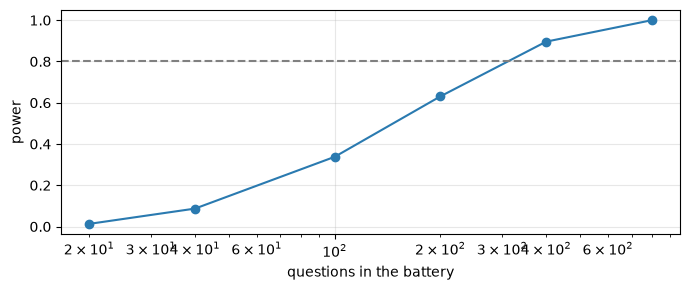

In [10]:
from scipy.stats import binomtest
rng = np.random.default_rng(1)

def power(n_q, p_ab=0.05, p_ba=0.12, sims=1000):
    hits = 0
    for _ in range(sims):
        ab, ba, _ = rng.multinomial(n_q, [p_ab, p_ba, 1 - p_ab - p_ba])
        if ab + ba and binomtest(int(ba), int(ab + ba), 0.5).pvalue < 0.05:
            hits += 1
    return hits / sims

sizes = [20, 40, 100, 200, 400, 800]
pw = [power(n) for n in sizes]
for n_q, p in zip(sizes, pw):
    print(f"{n_q:4d} questions: a true 7-point improvement is detected {p:5.0%} of the time")
fig, ax = plt.subplots(figsize=(7, 3)); ax.plot(sizes, pw, "o-", color="#2a7ab0"); ax.axhline(0.8, ls="--", color="grey")
ax.set_xscale("log"); ax.set_xlabel("questions in the battery"); ax.set_ylabel("power"); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

El objetivo estándar es una potencia del 80 %. Una batería de cuarenta preguntas detecta una mejora de siete
puntos con mucha menos frecuencia, así que las diferencias de unas pocas preguntas en una batería de este
tamaño deben presentarse como *"sin diferencia detectable"*, no como una victoria. De ahí salen dos reglas
prácticas: **haz crecer la batería** siempre que una decisión dependa de una diferencia pequeña (el tráfico de
producción es la mejor fuente de preguntas nuevas, que es justo lo que automatiza el módulo 08), y **mira los
fallos uno por uno**, porque un puñado de fallos entendidos enseña más que una décima de precisión.

## 8. Antes y después, con preguntas que el arreglo no ha visto

Ahora reparamos los fallos que muestra el conjunto 1 y medimos en ambos conjuntos. Dos arreglos, ambos
encontrados leyendo el conjunto 1:

1. **Guarda de entidades**: se rechaza una pregunta que nombra una turbina que no existe (`HV99`). Esto
   resuelve una trampa.
2. **Expansión de vocabulario**: añadir las palabras del propio manual junto a las del usuario (*boats* con
   *vessels*, *qualification* con *certificate*, *ashore* con *onshore export*...), tomadas de los fallos del
   conjunto 1.

La prueba honesta es el **conjunto 2**, escrito después de diseñar los arreglos: no se usó para elegirlos.

In [11]:
SYN = {"boats": "vessels", "boat": "vessel", "qualification": "certificate", "ashore": "onshore export", "alone": "lone",
       "blackout": "grid loss", "dolphin": "marine mammal", "autumn": "october march migration", "injury": "injury near miss"}
def expand(question):
    extra = [v for k, v in SYN.items() if re.search(rf"\b{k}\b", question, re.I)]
    return question + " " + " ".join(extra)

B_fix = build_system(hybrid, lambda q, e: bm25.scores(e).max() < 1.0 and sem(e).max() < 0.30, expand=expand, entity_guard=True)
A_fix = build_system(bm25.scores, lambda q, e: bm25.scores(e).max() < 1.0, expand=expand, entity_guard=True)

systems = {"A": A, "A+fix": A_fix, "B": B, "B+fix": B_fix}
for label, battery in [("set 1 (used to design the fixes)", SET1), ("set 2 (written after, held out)", SET2)]:
    res = {n: run_all(s, battery) for n, s in systems.items()}
    m = metrics(res, battery)
    print(label)
    print(f"{'system':>8s}{'correct':>9s}{'of':>4s}{'hit@1':>8s}{'MRR':>7s}{'refusal rec':>13s}")
    for n, v in m.items():
        print(f"{n:>8s}{int(round(v['correct'] * len(battery))):9d}{len(battery):4d}{v['hit1']:8.2f}{v['mrr']:7.2f}{v['ref_rec']:13.2f}")
    print()

set 1 (used to design the fixes)
  system  correct  of   hit@1    MRR  refusal rec
       A       15  20    0.81   0.90         0.50
   A+fix       18  20    0.94   0.96         0.75
       B       16  20    0.94   0.97         0.25
   B+fix       18  20    1.00   1.00         0.50



set 2 (written after, held out)
  system  correct  of   hit@1    MRR  refusal rec
       A       10  20    0.62   0.70         0.00
   A+fix       12  20    0.69   0.75         0.25
       B       12  20    0.75   0.86         0.00
   B+fix       14  20    0.81   0.90         0.25



Compara los dos bloques como lo hizo la evaluación real (el conjunto 1 antes y después de sus arreglos, y luego
el conjunto 2 escrito después). La mejora en el **conjunto 1** es en parte un artefacto: diseñamos los arreglos
mirándolo (A pasa de 15 a 18 correctas, B de 16 a 18). Los números del **conjunto 2** son los honestos: ambos
sistemas ganan allí también dos preguntas (A de 10 a 12, B de 12 a 14), así que la reparación generalizó al
menos un poco. Pero dos preguntas de veinte están dentro del ruido de la sección 7, y la mayoría de los fallos
restantes siguen sin tocarse: las trampas sin un identificador que comprobar (*stock price*, *how many people
work on the farm*) y las paráfrasis cuyas palabras no están en nuestra pequeña lista de sinónimos. Digan lo que
digan las cifras, preséntalas tal como son. Un arreglo que ayuda en el conjunto 1 y no hace nada en el
conjunto 2 solo ha memorizado el conjunto 1.

Como referencia, el agente real del parque eólico evaluado así pasó de **5 de 15** a **13 de 15** correctas en
su primer conjunto tras los arreglos, y en un segundo conjunto de 20 preguntas escritas después (con trampas
como una turbina que no existe y un resultado nunca calculado) de **12 de 20** a **20 de 20**. El segundo
conjunto importó más que el primero: es lo que mostró que los arreglos eran reales.

## Ejercicios

1. Añade cinco preguntas tuyas al conjunto 2 (una trampa, dos paráfrasis, un identificador, una directa).
   Vuelve a ejecutar la sección 8. ¿Cambia la conclusión?
2. Añade tolerancia del estilo `10 minutes?` a un patrón y rompe otro: escribe un patrón demasiado débil y uno
   demasiado estricto, y encuéntralos con la lista de discrepancias de la sección 4.
3. En `faithfulness`, cambia el umbral de apoyo de 0.6 a 0.3 y a 0.9. ¿Qué muestras de las seis cambian de
   veredicto y qué ajuste usarías para un manual de seguridad?
4. Cambia `p_ab` y `p_ba` en `power` a una mejora de 3 puntos. ¿Qué tamaño debe tener ahora la batería?